<a href="https://colab.research.google.com/github/1322vishav/Image-Processing/blob/main/Assignment5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import cv2
import numpy as np
import matplotlib.pyplot as plt

IMG_PATH = '/content/drive/MyDrive/image.jpg'
REF_PATH = '/content/drive/MyDrive/reference.jpg'

def load_gray(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not read {path}")
    return img

gray = load_gray(IMG_PATH)

Mounted at /content/drive


/tmp/ipykernel_777/4279925272.py:12: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  ax[1,0].hist(gray.ravel(), 256, [0, 256]); ax[1,0].set_title('Original histogram')
/tmp/ipykernel_777/4279925272.py:13: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  ax[1,1].hist(eq.ravel(),   256, [0, 256]); ax[1,1].set_title('Equalized histogram')


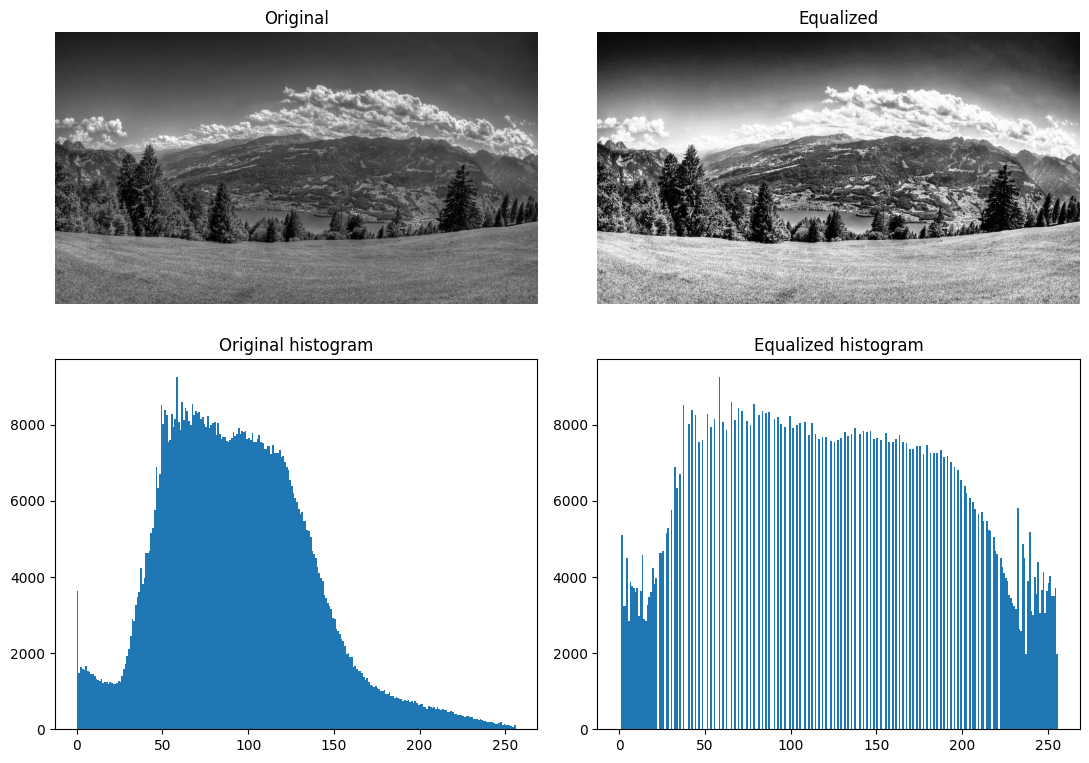

In [2]:
def equalize(img):
    hist = np.bincount(img.ravel(), minlength=256)
    cdf = np.cumsum(hist) / img.size                 # s = T(r)
    lut = np.round(255 * cdf).astype(np.uint8)
    return lut[img]

eq = equalize(gray)

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
ax[0,0].imshow(gray, cmap='gray', vmin=0, vmax=255); ax[0,0].set_title('Original'); ax[0,0].axis('off')
ax[0,1].imshow(eq,   cmap='gray', vmin=0, vmax=255); ax[0,1].set_title('Equalized'); ax[0,1].axis('off')
ax[1,0].hist(gray.ravel(), 256, [0, 256]); ax[1,0].set_title('Original histogram')
ax[1,1].hist(eq.ravel(),   256, [0, 256]); ax[1,1].set_title('Equalized histogram')
plt.tight_layout(); plt.show()

/tmp/ipykernel_777/2306558082.py:17: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  ax[1,i].hist(im.ravel(), 256, [0, 256]); ax[1,i].set_title(f'{t} histogram')


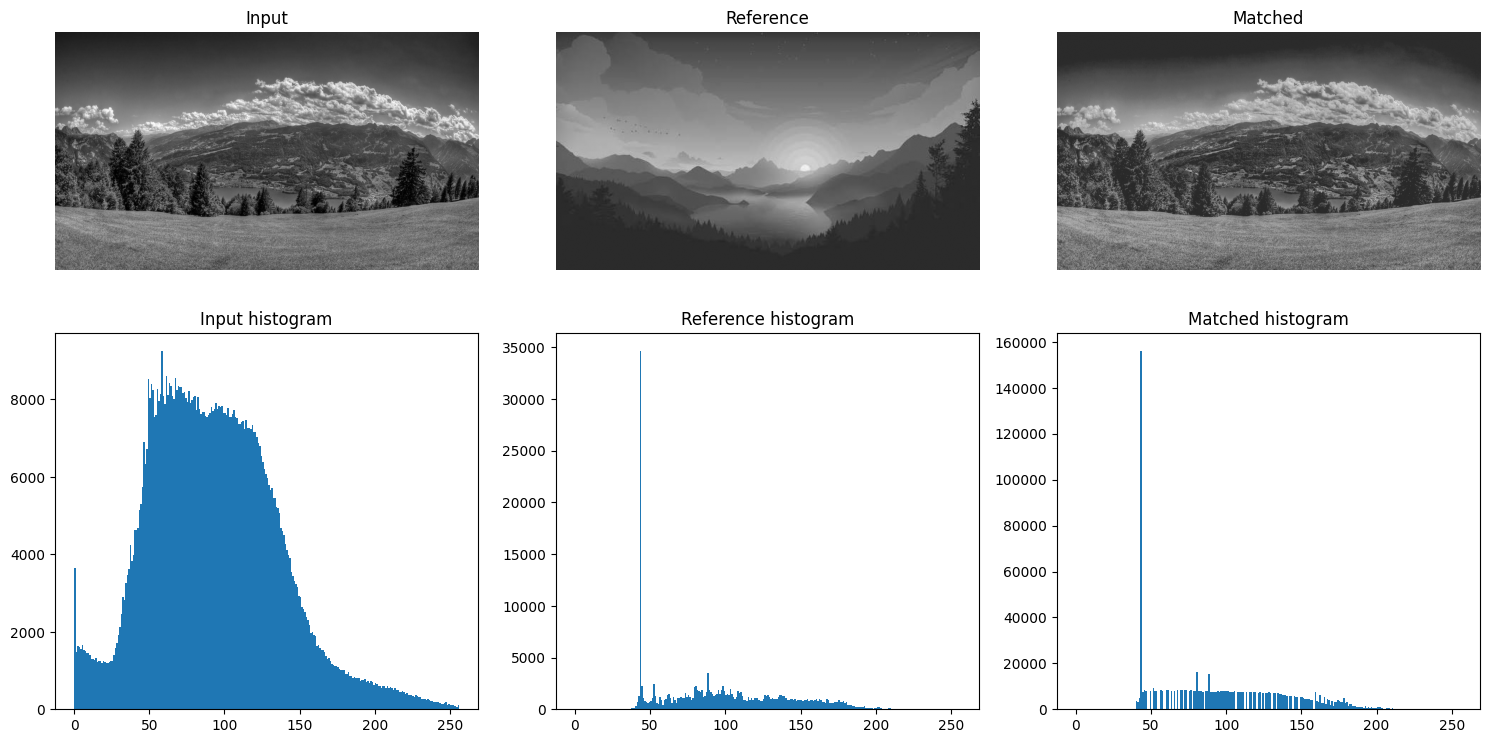

In [3]:
ref = load_gray(REF_PATH)

def match_histogram(src, ref):
    # T(r): equalizing transform of the source image
    # G(z): equalizing transform of the reference image
    # Matched level is z = G^-1(T(r)), i.e. the reference level whose CDF is closest to the source CDF
    cdf_s = np.cumsum(np.bincount(src.ravel(), minlength=256)) / src.size
    cdf_r = np.cumsum(np.bincount(ref.ravel(), minlength=256)) / ref.size
    lut = np.searchsorted(cdf_r, cdf_s, side='left').clip(0, 255).astype(np.uint8)
    return lut[src]

matched = match_histogram(gray, ref)

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for i, (im, t) in enumerate([(gray, 'Input'), (ref, 'Reference'), (matched, 'Matched')]):
    ax[0,i].imshow(im, cmap='gray', vmin=0, vmax=255); ax[0,i].set_title(t); ax[0,i].axis('off')
    ax[1,i].hist(im.ravel(), 256, [0, 256]); ax[1,i].set_title(f'{t} histogram')
plt.tight_layout(); plt.show()